Krzysztof Kata 254776  
Zadanie 3

Celem zadania jest analiza stężenia CO i prosta prognoza na kolejne 7 dni.

Źródło: https://archive.ics.uci.edu/dataset/360/air+quality.
Zbiór zawiera pomiary układu czujników gazu oraz analizatora referencyjnego.
Analizowana kolumna CO(GT) podaje stężenie CO z analizatora w mg/m³. Wartość -200 oznacza brak pomiaru.


In [ ]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

plik = "AirQualityUCI.zip"
if not Path(plik).exists():
    urlretrieve("https://archive.ics.uci.edu/static/public/360/air+quality.zip", plik)

with ZipFile(plik) as archiwum:
    dane = pd.read_csv(archiwum.open("AirQualityUCI.csv"), sep=";", decimal=",", na_values=-200)
dane = dane.dropna(subset=["Date", "Time"])
dane.index = pd.to_datetime(dane["Date"] + " " + dane["Time"], format="%d/%m/%Y %H.%M.%S")
dane = dane.sort_index()
co = dane["CO(GT)"].resample("D").mean()


Statystyki dotyczą pomiarów godzinowych. Wykres pokazuje średnie dzienne z dostępnych pomiarów. Dni bez odczytów pozostają puste.

Liczba pomiarów: 9357
Braki CO: 1683
mean     2.153
min      0.100
max     11.900
Name: CO(GT), dtype: float64


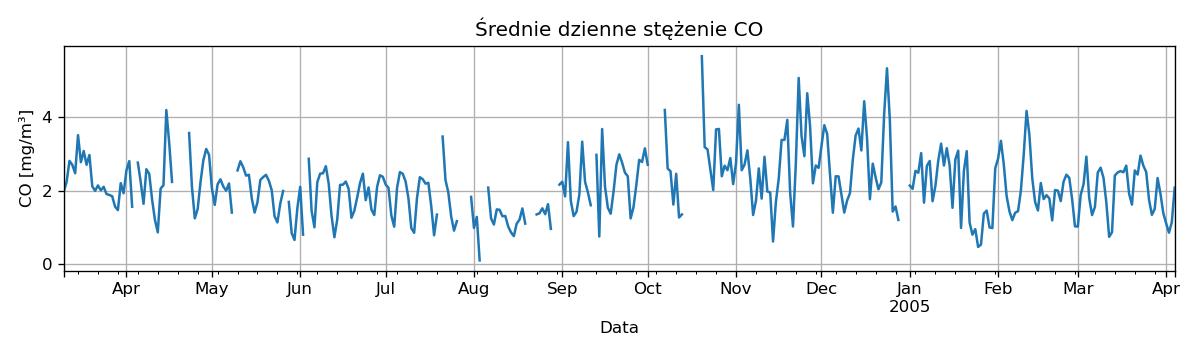

In [ ]:
print("Liczba pomiarów:", len(dane))
print("Braki CO:", dane["CO(GT)"].isna().sum())
print(dane["CO(GT)"].agg(["mean", "min", "max"]).round(3))

co.plot(figsize=(10, 3), title="Średnie dzienne stężenie CO", grid=True)
plt.xlabel("Data")
plt.ylabel("CO [mg/m³]")
plt.tight_layout()
plt.show()


Regresja liniowa uwzględnia trend czasowy i dzień tygodnia. Każdy dzień (osobna kolumna) ma osobną wartość 0/1, a niedziela jest punktem odniesienia.

Używamy ostatnich 30 dni i pomijamy dni bez pomiarów. Ostatnie 7 dni służy do sprawdzenia modelu. MAE to średni błąd w mg/m³. Następnie model uczy się na całym tym okresie i prognozuję kolejny tydzień.

MAE na ostatnich 7 dniach: 0.86 mg/m³
Trend po uwzględnieniu dnia tygodnia: -0.0098 mg/m³ na dobę
            Dzień  Prognoza CO [mg/m³]
2005-04-05     Wt                 2.27
2005-04-06     Śr                 2.33
2005-04-07    Czw                 2.06
2005-04-08     Pt                 1.82
2005-04-09    Sob                 1.14
2005-04-10  Niedz                 1.05
2005-04-11    Pon                 1.81


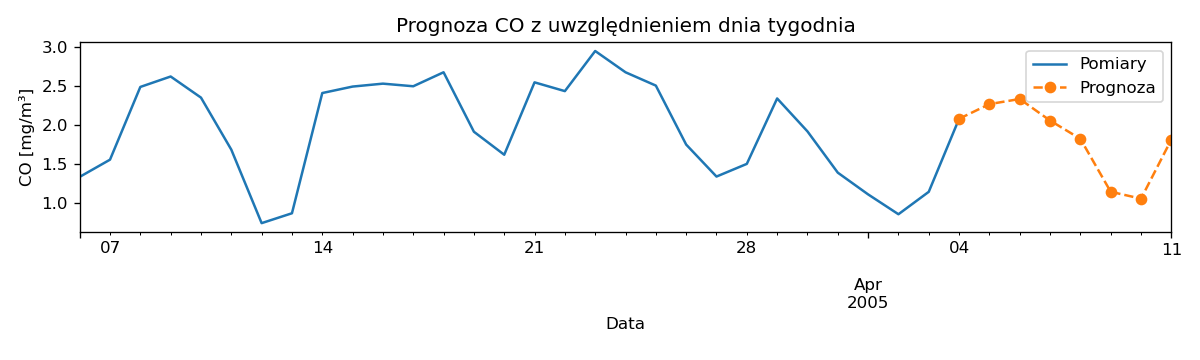

In [ ]:
ostatnie = co.loc[co.index >= co.index[-1] - pd.Timedelta(days=29)].dropna()

def cechy(daty):
    x = pd.DataFrame({"trend": (daty - ostatnie.index[0]).days}, index=daty)
    for dzien in range(6):
        x[f"dzien_{dzien}"] = (daty.dayofweek == dzien).astype(int)
    return x

x = cechy(ostatnie.index)
model = LinearRegression()
model.fit(x.iloc[:-7], ostatnie.iloc[:-7])
blad = mean_absolute_error(ostatnie.iloc[-7:], model.predict(x.iloc[-7:]))
print(f"MAE na ostatnich 7 dniach: {blad:.2f} mg/m³")

model.fit(x, ostatnie)
print(f"Trend po uwzględnieniu dnia tygodnia: {model.coef_[0]:+.4f} mg/m³ na dobę")
daty = pd.date_range(co.index[-1] + pd.Timedelta(days=1), periods=7)
prognoza = pd.Series(model.predict(cechy(daty)), index=daty)
nazwy = ["Pon", "Wt", "Śr", "Czw", "Pt", "Sob", "Niedz"]
print(pd.DataFrame({"Dzień": [nazwy[d] for d in daty.dayofweek], "Prognoza CO [mg/m³]": prognoza.round(2)}))

ostatnie.plot(figsize=(10, 3), label="Pomiary", grid=True)
pd.concat([ostatnie.iloc[-1:], prognoza]).plot(label="Prognoza", style="--o")
plt.title("Prognoza CO z uwzględnieniem dnia tygodnia")
plt.xlabel("Data")
plt.ylabel("CO [mg/m³]")
plt.legend()
plt.tight_layout()
plt.show()


Średnie stężenie CO wyniosło 2,153 mg/m³, minimum 0,1 mg/m³, a maksimum 11,9 mg/m³.
Prognoza na 5–11 kwietnia 2005 r. zmienia się zależnie od dnia tygodnia i wynosi od 1.05 do 2.33 mg/m³.
MAE wyniosło 0.86 mg/m³. To wynik jednego testu na 7 dniach, więc prognoza jest orientacyjna.
